# 06 — Our method against full-wave solvers on small bodies

**Question.** How close is our forward method $R\,Q^{-1}TQ\,R$ to a complete Maxwell solution when the lens is only a few wavelengths across, and where does it stop being valid?

| Method | What it solves |
|---|---|
| **Ours** | One forward pass: local Fresnel transmission at each surface, exact angular-spectrum propagation between them, forward light exchange across the rim of thick lenses. No reflections inside the lens. |
| **BEM** | The complete scattering problem of the closed glass body (PMCHWT boundary integral equations on a triangle mesh): all reflections, rim and sidewall scattering. |
| **Mie** | The exact solution for a sphere. |

BEM is the reference for lenses; Mie checks BEM on spheres. All bodies are glass ($n = 1.5$) in air, lit by a unit x-polarized plane wave at $\lambda_0 = 532$ nm. Macroscopic sizes, where BEM cannot run, are validated against exact fields in notebook 07.

In [1]:
%matplotlib inline
import warnings

import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from IPython.display import Markdown, display
from matplotlib.colors import Normalize
from vecdiff_general.propagation.references.benchmarks import illumination

import lens_references as refs

warnings.simplefilter("ignore")
WAVELENGTH = refs.WAVELENGTH
plt.rcParams.update({"figure.dpi": 110})


def table(caption, header, rows):
    lines = [caption, "", "| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def percent(value):
    return "—" if value is None else f"{100 * value:.1f} %"


## 1. A flat interface

For a flat air–glass interface our operators must reproduce the exact Fresnel solution; this checks the implementation before any curvature enters.

In [2]:
air, glass = illumination(WAVELENGTH)
axis = (np.arange(32) - 16) * WAVELENGTH / 2
plane = optics.CartesianGrid(axis, axis)
kx = 2 * np.pi / (len(axis) * (axis[1] - axis[0])) * 3
k0 = 2 * np.pi / WAVELENGTH
source = optics.PlaneWaveExpansion([[kx, 0, np.sqrt(k0**2 - kx**2)]], [[0, 1, 0]], [0, 0, 0], WAVELENGTH, air.region)
interface = optics.DielectricInterface(optics.Plane(), air.region, glass)
ours = optics.propagate_interfaces(source, optics.OpticalSystem((interface,)), plane)
exact = optics.scatter_plane(source, optics.PlanarInterface(optics.Frame(), air.region, glass))
observation = plane.translated([0, 0, 3 * WAVELENGTH])
reference = exact.transmitted.evaluate(observation).electric.values
plane_error = np.linalg.norm(ours.evaluate(observation).electric.values - reference) / np.linalg.norm(reference)
print(f"Oblique plane wave on a flat interface: relative error of the transmitted E, ours vs exact Fresnel = {plane_error:.1e}")
assert plane_error < 1e-8

Oblique plane wave on a flat interface: relative error of the transmitted E, ours vs exact Fresnel = 4.0e-15


## 2. Is BEM a trustworthy reference?

On spheres BEM can be compared with the exact Mie solution. The error is the relative difference of the complex field $\mathbf E$ over the whole meridional section behind the sphere ($y=0$, $|x| \le 1.6R$, up to several radii downstream).

In [3]:
rows = []
for diameter in refs.SPHERE_SUBDIVISIONS:
    for row in refs.sphere_reference(diameter):
        rows.append((f"{diameter:g}", row["triangles"], percent(row["error"]), percent(row["change"]), f"{row['seconds']:.2f}"))
table(
    "**BEM against Mie on glass spheres.** Error: relative difference of complex E over the meridional section behind the sphere. "
    "Change: difference from the previous (coarser) mesh.",
    ("Sphere diameter (λ₀)", "BEM mesh (triangles)", "BEM error vs Mie", "Change from coarser mesh", "BEM assembly + solve (s)"),
    rows,
)
control, control_info = refs.sphere_control(verbose=False)
axial = np.linalg.norm(control["bem"] - control["mie"]) / np.linalg.norm(control["mie"])
print(f"6 λ₀ sphere, BEM at λ₀/3 elements ({control_info['unknowns']} unknowns) vs Mie on the axis behind it: {100 * axial:.1f} %")

**BEM against Mie on glass spheres.** Error: relative difference of complex E over the meridional section behind the sphere. Change: difference from the previous (coarser) mesh.

| Sphere diameter (λ₀) | BEM mesh (triangles) | BEM error vs Mie | Change from coarser mesh | BEM assembly + solve (s) |
|---|---|---|---|---|
| 0.6 | 80 | 2.5 % | — | 0.03 |
| 0.6 | 320 | 0.6 % | 1.9 % | 0.18 |
| 0.6 | 1280 | 0.1 % | 0.5 % | 2.22 |
| 1.2 | 80 | 6.3 % | — | 0.04 |
| 1.2 | 320 | 1.7 % | 4.7 % | 0.20 |
| 2 | 80 | 51.3 % | — | 0.03 |
| 2 | 320 | 3.6 % | 49.8 % | 0.19 |

6 λ₀ sphere, BEM at λ₀/3 elements (7836 unknowns) vs Mie on the axis behind it: 6.9 %


BEM converges toward Mie as its mesh is refined, so on bodies of this size it is a usable reference; its own refinement change is reported next to every lens comparison below.

## 3. Lenses of 1–4 wavelengths

Plano-convex and biconvex lenses of diameter $D$, surface radius $2D$, centre thickness $0.3D$. Our field: an FFT cell 24 clear radii wide, 384 samples per axis. Errors are relative differences of the complex $\mathbf E$ against the finer BEM mesh over

* the **meridional section** $y=0$ behind the lens ($|x|\le 1.6a$, $a$ the clear radius), and
* the **focal plane** at the axial maximum of BEM, whose window holds three secondary maxima on each side.

Our method leaves out what BEM includes: reflections inside the lens and scattering by its sidewall. At these sizes they are not small, so the differences below are mainly **model** differences, not numerical error.

In [4]:
lenses = {(shape, D): refs.small_lens(shape, D) for shape in refs.SMALL_SHAPES for D in refs.SMALL_DIAMETERS}
rows = []
for (shape, D), d in lenses.items():
    rows.append((shape, f"{D:g}", percent(d["error_section"]), percent(d["error_focal"]), f"{d['peak_ratio']:.2f}",
                 percent(d["bem_change_section"]), f"{d['seconds_ours']:.1f}", f"{d['seconds_bem']:.1f}"))
table(
    "**Ours against BEM.** Errors: relative difference of complex E. Peak ratio: focal intensity of ours divided by BEM's at the centre of the focal plane. "
    "BEM change: difference between its two meshes over the section (how far BEM itself is from convergence). Times are wall-clock seconds on this machine.",
    ("Lens", "Diameter (λ₀)", "Error over the meridional section", "Error over the focal plane", "Focal peak ratio, ours / BEM",
     "BEM change under mesh refinement", "Ours time (s)", "BEM assembly + solve (s)"),
    rows,
)

**Ours against BEM.** Errors: relative difference of complex E. Peak ratio: focal intensity of ours divided by BEM's at the centre of the focal plane. BEM change: difference between its two meshes over the section (how far BEM itself is from convergence). Times are wall-clock seconds on this machine.

| Lens | Diameter (λ₀) | Error over the meridional section | Error over the focal plane | Focal peak ratio, ours / BEM | BEM change under mesh refinement | Ours time (s) | BEM assembly + solve (s) |
|---|---|---|---|---|---|---|---|
| plano-convex | 1 | 5.4 % | 3.4 % | 1.14 | 0.1 % | 1.1 | 1.2 |
| plano-convex | 2 | 11.0 % | 8.9 % | 1.11 | 0.6 % | 1.1 | 1.2 |
| plano-convex | 4 | 11.7 % | 9.8 % | 1.06 | 10.0 % | 1.5 | 1.3 |
| biconvex | 1 | 6.9 % | 3.1 % | 1.17 | 0.2 % | 1.7 | 1.2 |
| biconvex | 2 | 11.8 % | 8.1 % | 1.10 | 0.3 % | 2.0 | 1.3 |
| biconvex | 4 | 11.8 % | 9.8 % | 1.21 | 4.6 % | 2.4 | 1.2 |

The fields of the largest lenses, $D = 4\lambda_0$. Ours and BEM share one linear colour scale in each row, so equal colours mean equal intensity. The difference map uses its own scale.

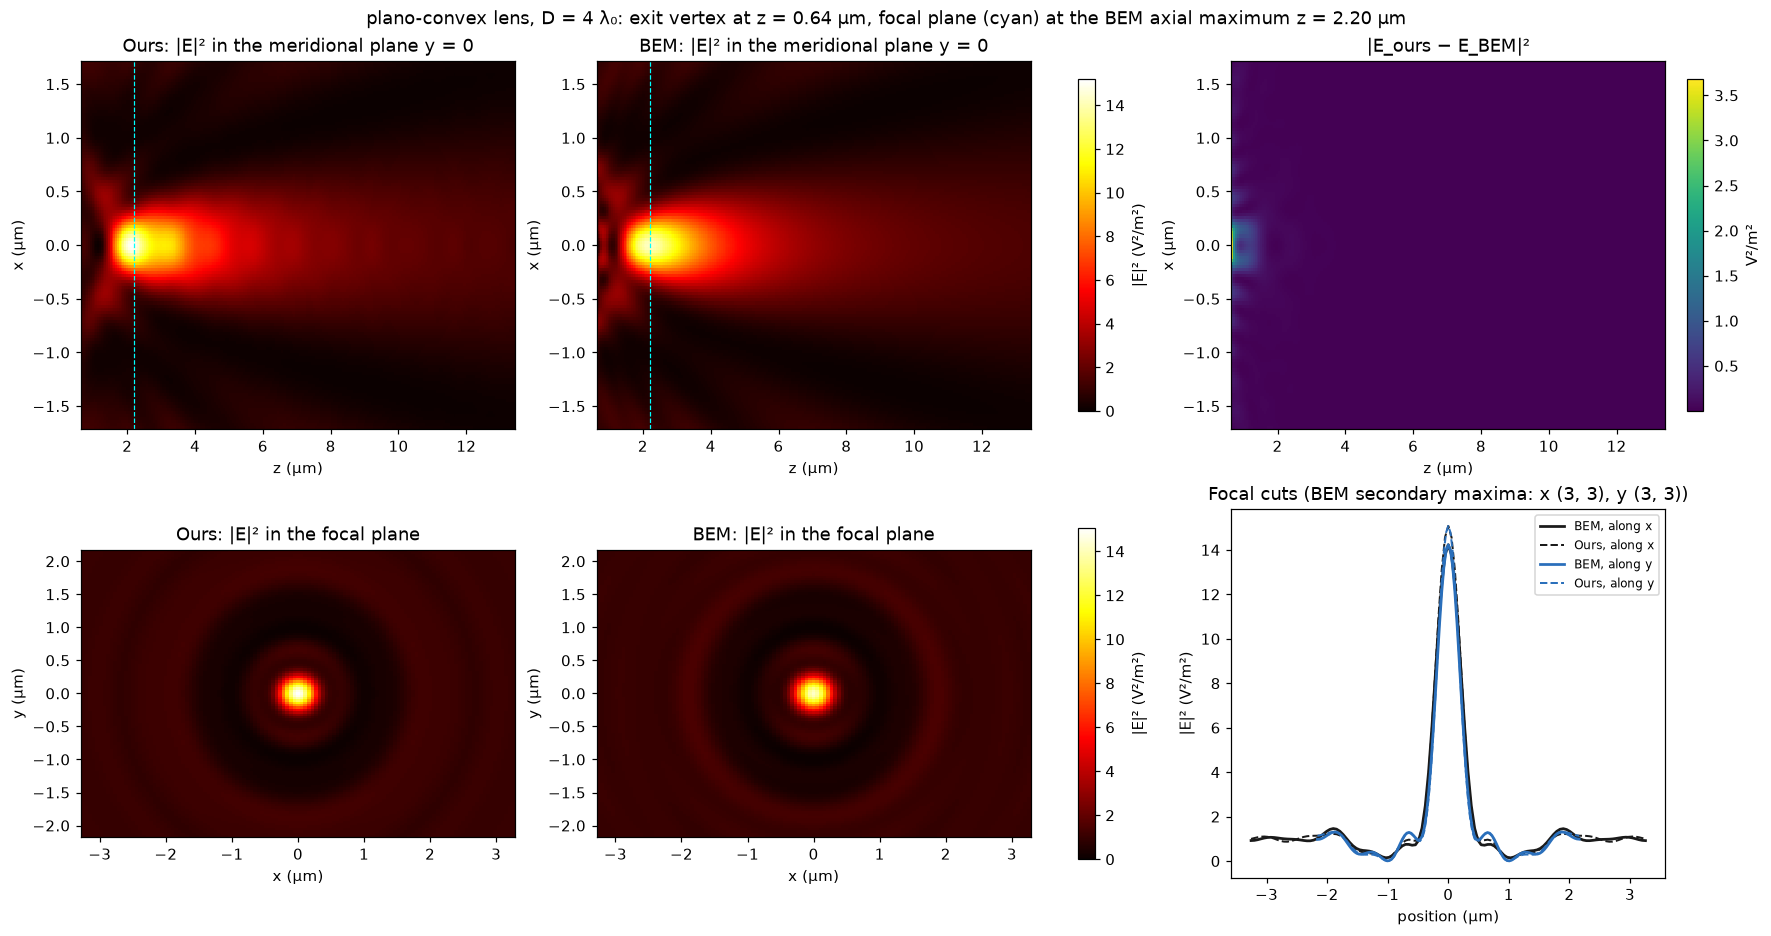

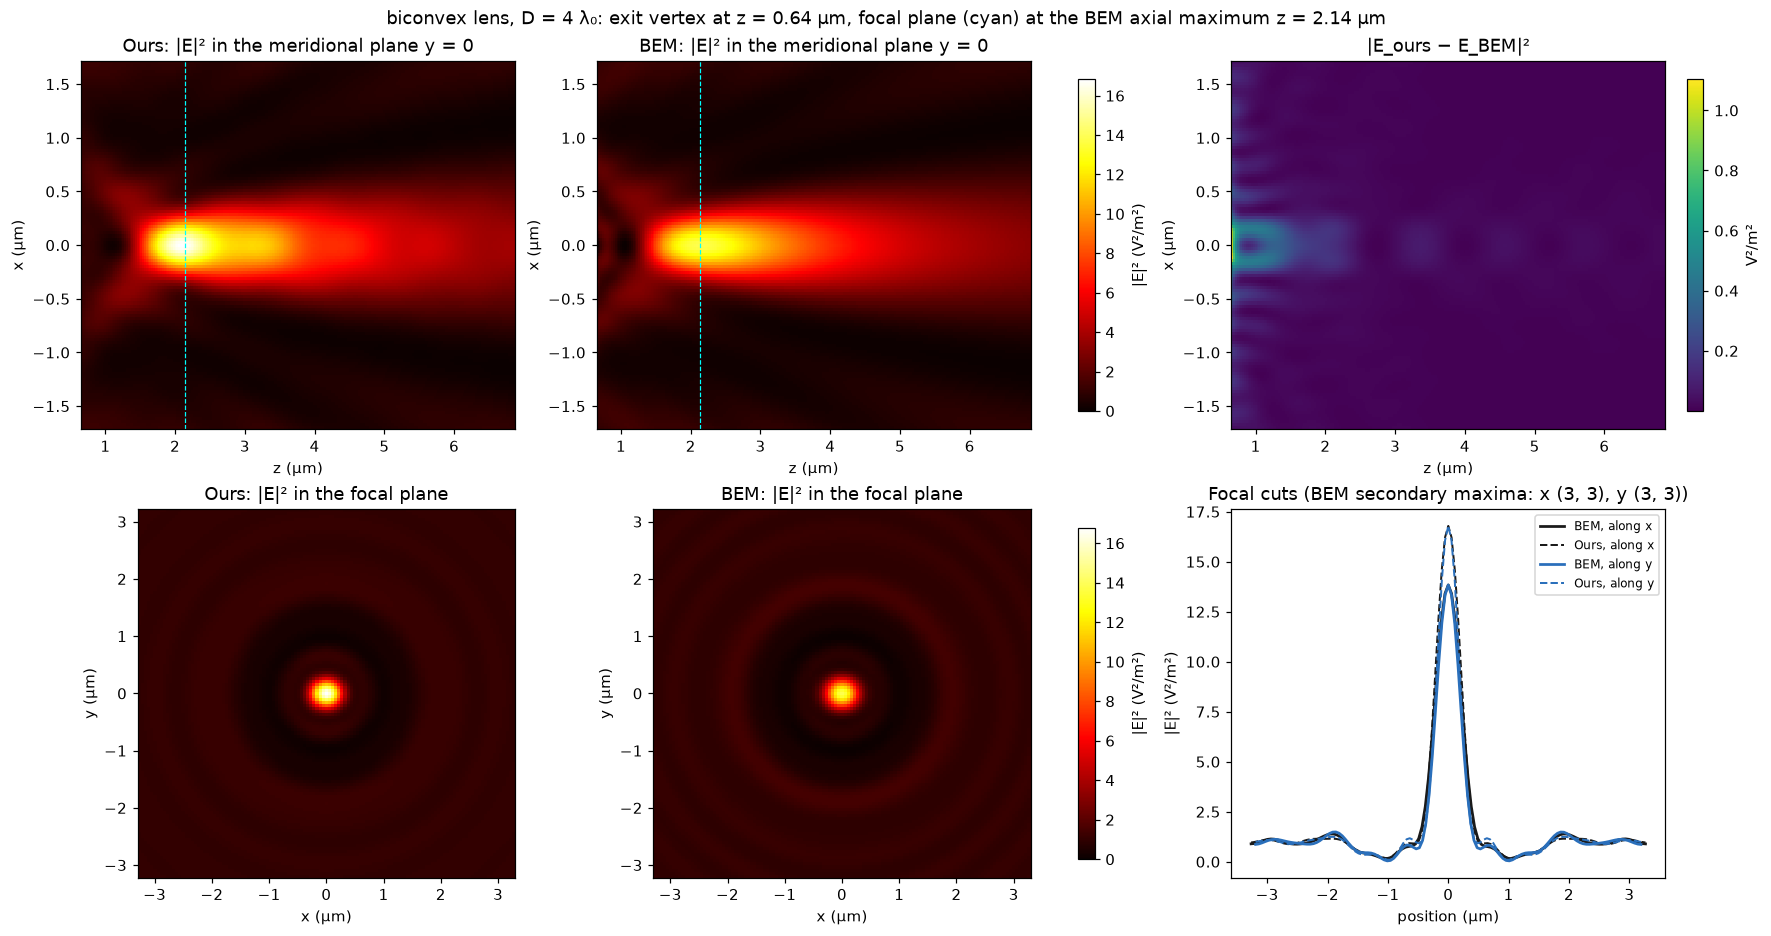

In [5]:
def count_maxima(cut):
    m = len(cut) // 2
    inner = np.arange(1, len(cut) - 1)
    peaks = inner[(cut[inner] > cut[inner - 1]) & (cut[inner] >= cut[inner + 1])]
    return int(np.sum(peaks < m - 1)), int(np.sum(peaks > m + 1))


def lens_figure(shape, D):
    d = lenses[(shape, D)]
    um = 1e6
    fine = refs.SMALL_BEM_DIVISORS[-1]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8.4), layout="constrained")
    Z, X = np.meshgrid(d["z"] * um, d["x"] * um)
    ours, bem = np.sum(abs(d["section_ours"]) ** 2, -1), np.sum(abs(d[f"section_{fine}"]) ** 2, -1)
    scale = Normalize(0, max(ours.max(), bem.max()))
    for ax, values, title in ((axes[0, 0], ours, "Ours"), (axes[0, 1], bem, "BEM")):
        im = ax.pcolormesh(Z, X, values, cmap="hot", norm=scale, shading="nearest")
        ax.axvline(d["focus"] * um, color="cyan", ls="--", lw=0.8)
        ax.set(title=f"{title}: |E|² in the meridional plane y = 0", xlabel="z (µm)", ylabel="x (µm)")
    fig.colorbar(im, ax=axes[0, :2], label="|E|² (V²/m²)", shrink=0.9)
    difference = np.sum(abs(d["section_ours"] - d[f"section_{fine}"]) ** 2, -1)
    im = axes[0, 2].pcolormesh(Z, X, difference, cmap="viridis", shading="nearest")
    axes[0, 2].set(title="|E_ours − E_BEM|²", xlabel="z (µm)", ylabel="x (µm)")
    fig.colorbar(im, ax=axes[0, 2], label="V²/m²", shrink=0.9)
    FX, FY = np.meshgrid(d["fx"] * um, d["fy"] * um)
    ours, bem = np.sum(abs(d["focal_ours"]) ** 2, -1), np.sum(abs(d[f"focal_{fine}"]) ** 2, -1)
    scale = Normalize(0, max(ours.max(), bem.max()))
    for ax, values, title in ((axes[1, 0], ours, "Ours"), (axes[1, 1], bem, "BEM")):
        im = ax.pcolormesh(FX, FY, values, cmap="hot", norm=scale, shading="nearest")
        ax.set(aspect="equal", title=f"{title}: |E|² in the focal plane", xlabel="x (µm)", ylabel="y (µm)")
    fig.colorbar(im, ax=axes[1, :2], label="|E|² (V²/m²)", shrink=0.9)
    cy, cx = len(d["fy"]) // 2, len(d["fx"]) // 2
    ax = axes[1, 2]
    for coord, sl, label, color in ((d["fx"], np.s_[cy, :], "x", "0.1"), (d["fy"], np.s_[:, cx], "y", "#2a6fbb")):
        ax.plot(coord * um, bem[sl], "-", color=color, lw=1.8, label=f"BEM, along {label}")
        ax.plot(coord * um, ours[sl], "--", color=color, lw=1.3, label=f"Ours, along {label}")
    lobes_x = count_maxima(np.sum(abs(d[f"focal_{fine}"][cy, :, :2]) ** 2, -1))
    lobes_y = count_maxima(np.sum(abs(d[f"focal_{fine}"][:, cx, :2]) ** 2, -1))
    ax.set(xlabel="position (µm)", ylabel="|E|² (V²/m²)", title=f"Focal cuts (BEM secondary maxima: x {lobes_x}, y {lobes_y})")
    ax.legend(fontsize=8)
    fig.suptitle(f"{shape} lens, D = {D:g} λ₀: exit vertex at z = {float(d['exit_z']) * um:.2f} µm, "
                 f"focal plane (cyan) at the BEM axial maximum z = {float(d['focus']) * um:.2f} µm")
    plt.show()
    return lobes_x, lobes_y


for shape in refs.SMALL_SHAPES:
    assert lens_figure(shape, 4.0) == ((3, 3), (3, 3))

## 4. Thicker lenses: when does rim coupling help?

In a thick lens, light near the rim crosses between glass and air on its way to the exit. Our method can exchange light across the rim in thin steps ("coupled") instead of carrying the glass and air parts separately ("separated"). It switches coupling on automatically when the element Fresnel number $a^2/(\lambda_0 T)$ ($a$ clear radius, $T$ centre thickness) is at most 8. The lenses here are $6\lambda_0$ across; the reference is BEM with $\lambda_0/4$ elements, first checked against Mie on a $6\lambda_0$ sphere (left).

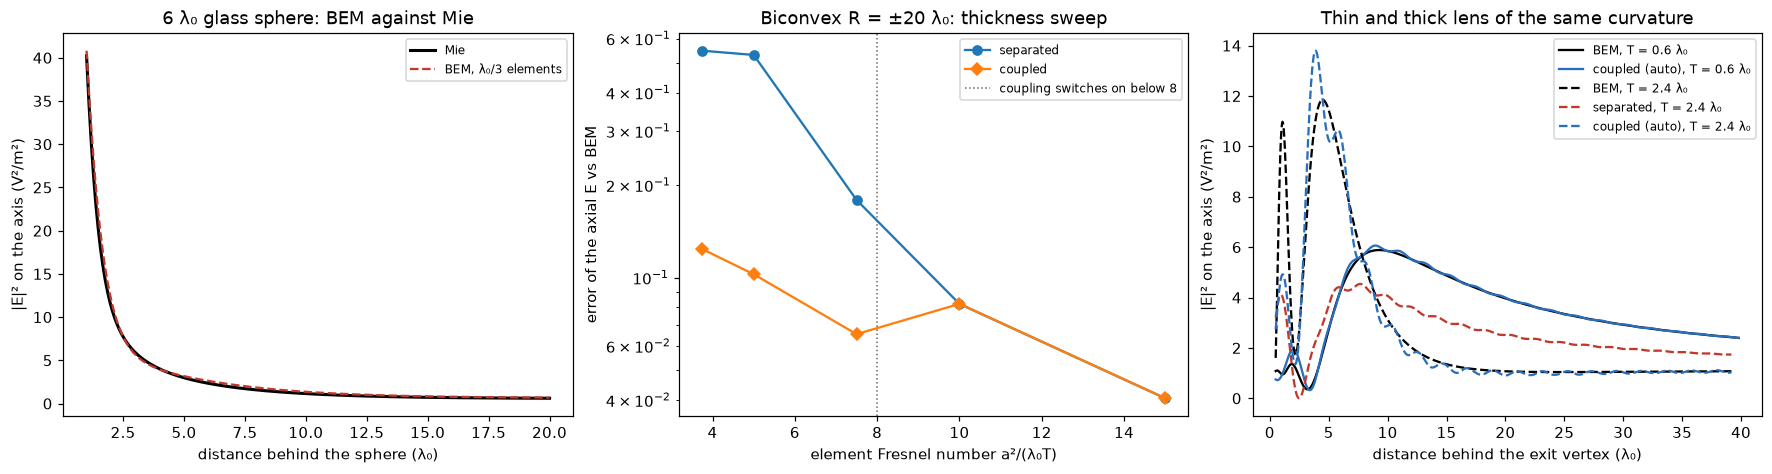

**Ours against BEM on 6 λ₀ lenses.** Errors: relative difference of the complex E on the axis, from one wavelength behind the exit vertex. Coupled is what the method uses when a²/(λ₀T) ≤ 8; above that both columns coincide.

| Lens | Centre thickness T (λ₀) | Element Fresnel number a²/(λ₀T) | Error, separated | Error, coupled | BEM change, λ₀/3 → λ₀/4 elements |
|---|---|---|---|---|---|
| biconvex R20, T 0.6 | 0.6 | 15.0 | 4.1 % | 4.1 % | 0.6 % |
| biconvex R20, T 0.9 | 0.9 | 10.0 | 8.2 % | 8.2 % | 0.5 % |
| biconvex R20, T 1.2 | 1.2 | 7.5 | 17.9 % | 6.6 % | 1.5 % |
| biconvex R20, T 1.8 | 1.8 | 5.0 | 53.1 % | 10.3 % | 3.5 % |
| biconvex R20, T 2.4 | 2.4 | 3.8 | 54.8 % | 12.4 % | 5.4 % |
| thin plano-convex | 0.7 | 12.9 | 3.7 % | 3.7 % | 1.0 % |
| thin convex-plano | 0.7 | 12.9 | 3.5 % | 3.5 % | 0.7 % |
| thin biconvex | 0.7 | 12.9 | 3.7 % | 3.7 % | 0.7 % |
| thin asymmetric biconvex | 0.7 | 12.9 | 3.4 % | 3.4 % | 0.9 % |

In [6]:
control, info = refs.sphere_control(verbose=False)
behind = control["z"] / WAVELENGTH - refs.DIAMETER / 2
results = {name: refs.validity(name) for name in refs.SWEEP + refs.MAIN}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), layout="constrained")
axes[0].plot(behind, np.sum(abs(control["mie"]) ** 2, -1), color="black", lw=2, label="Mie")
axes[0].plot(behind, np.sum(abs(control["bem"]) ** 2, -1), color="#c0392b", ls="--", label="BEM, λ₀/3 elements")
axes[0].set(xlabel="distance behind the sphere (λ₀)", ylabel="|E|² on the axis (V²/m²)", title="6 λ₀ glass sphere: BEM against Mie")
axes[0].legend(fontsize=8)
for label, key, marker in (("separated", "error_uncoupled", "o"), ("coupled", "error", "D")):
    axes[1].plot([refs.element_fresnel(n) for n in refs.SWEEP], [results[n][key] for n in refs.SWEEP], marker + "-", ms=6, label=label)
axes[1].axvline(8, color="0.4", ls=":", lw=1, label="coupling switches on below 8")
axes[1].set(xlabel="element Fresnel number a²/(λ₀T)", ylabel="error of the axial E vs BEM", yscale="log",
            title="Biconvex R = ±20 λ₀: thickness sweep")
axes[1].legend(fontsize=8)
for name, style in ((refs.SWEEP[0], "-"), (refs.SWEEP[-1], "--")):
    data, T = results[name], refs.LENSES[name][2]
    z = data["z"] / WAVELENGTH - T
    axes[2].plot(z, np.sum(abs(data["bem"]) ** 2, -1), color="black", ls=style, label=f"BEM, T = {T:g} λ₀")
    if name == refs.SWEEP[-1]:
        axes[2].plot(z, np.sum(abs(data["uncoupled"]) ** 2, -1), color="#c0392b", ls=style, label=f"separated, T = {T:g} λ₀")
    axes[2].plot(z, np.sum(abs(data["ours"]) ** 2, -1), color="#2a6fbb", ls=style, label=f"coupled (auto), T = {T:g} λ₀")
axes[2].set(xlabel="distance behind the exit vertex (λ₀)", ylabel="|E|² on the axis (V²/m²)", title="Thin and thick lens of the same curvature")
axes[2].legend(fontsize=8)
plt.show()

rows = [(name, f"{refs.LENSES[name][2]:g}", f"{refs.element_fresnel(name):.1f}", percent(results[name]["error_uncoupled"]),
         percent(results[name]["error"]), percent(results[name]["bem_change"])) for name in refs.SWEEP + refs.MAIN]
table(
    "**Ours against BEM on 6 λ₀ lenses.** Errors: relative difference of the complex E on the axis, from one wavelength behind the exit vertex. "
    "Coupled is what the method uses when a²/(λ₀T) ≤ 8; above that both columns coincide.",
    ("Lens", "Centre thickness T (λ₀)", "Element Fresnel number a²/(λ₀T)", "Error, separated", "Error, coupled", "BEM change, λ₀/3 → λ₀/4 elements"),
    rows,
)

## Conclusions

* **Flat interface:** our operators reproduce exact Fresnel transmission to $4\times10^{-15}$.
* **BEM is a usable reference at these sizes.** On spheres it converges toward Mie (0.1 % at $0.6\lambda_0$ with 1280 triangles, 2–4 % at $1.2$–$2\lambda_0$ with 320). On the $4\lambda_0$ lenses its own mesh change (5–10 %) is as large as its difference from us, so there the comparison is limited by BEM.
* **Ours against BEM on 1–4 λ₀ lenses:** 3–10 % over the focal plane and 5–12 % over the meridional section. The focal spot, its side lobes and the far field agree; the differences sit just behind the lens, where BEM includes reflections inside the lens and sidewall scattering that our forward model omits. Our focal peak is 6–21 % higher.
* **Thick lenses need rim coupling:** for $a^2/(\lambda_0T)\le 5$ it lowers the error from 53–55 % to 10–12 %. Thin lenses ($a^2/(\lambda_0T) = 12.9$) are within 3.4–3.7 % without it.
* **Cost:** at these sizes both methods take 1–2.5 s. BEM's dense system grows steeply with size ($6\lambda_0$ lenses already need about 8000 unknowns); ours does not. Macroscopic accuracy, where BEM cannot run, is established against exact Maxwell fields in notebook 07.